In [1]:
from pathlib import Path

import numpy as np
import skrf as rf
from matplotlib import pyplot as plt
from pyhamtools import frequency as fr

plt.style.use("bmh")
print(plt.style.available)

['Solarize_Light2', '_classic_test_patch', '_mpl-gallery', '_mpl-gallery-nogrid', 'bmh', 'classic', 'dark_background', 'fast', 'fivethirtyeight', 'ggplot', 'grayscale', 'seaborn-v0_8', 'seaborn-v0_8-bright', 'seaborn-v0_8-colorblind', 'seaborn-v0_8-dark', 'seaborn-v0_8-dark-palette', 'seaborn-v0_8-darkgrid', 'seaborn-v0_8-deep', 'seaborn-v0_8-muted', 'seaborn-v0_8-notebook', 'seaborn-v0_8-paper', 'seaborn-v0_8-pastel', 'seaborn-v0_8-poster', 'seaborn-v0_8-talk', 'seaborn-v0_8-ticks', 'seaborn-v0_8-white', 'seaborn-v0_8-whitegrid', 'tableau-colorblind10']


In [2]:
def is_ham_frequency(f):
    try:
        r = fr.freq_to_band(f / 1e3)["band"]
    except KeyError as ke:
        r = np.nan
    return r

def s11_to_vswr(s11):
    # reflection coefficient is magnitude of s11
    #   r_c goes epslion over 1 due to numerical error and exactly 1 makes the vswr infinite
    rc = np.clip(np.abs(s11), 0, 1 - 1e-8)
    vswr = (1 + rc) / (1 - rc)
    return vswr

In [24]:
fr.freq_to_band

<function pyhamtools.frequency.freq_to_band(freq)>

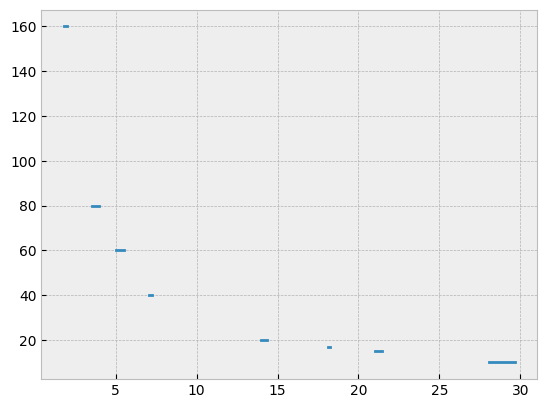

In [3]:
freq_range = rf.Frequency(1, 30, npoints=505, unit='MHz')

ham_freqs = np.array(list(map(is_ham_frequency, freq_range.f)))

plt.plot(freq_range.f/1e6, ham_freqs)


In [4]:
# data_files = Path("/Users/heller/dev/instant_tune/data")

project_dir = Path.cwd()
data_files = project_dir / "data"

tuner_files = data_files / "tuners"
antenna_files = data_files / "antennas"
calib_files = data_files / "vna_calibrations"

In [5]:
# load the calibration
calib = rf.Network(calib_files / "cal-1-30MHz-505pts.s2p")
calib.s[:, 0, 0][:10]

array([-0.00539154-0.00158579j, -0.00565685-0.00167291j,
       -0.00552415-0.00130934j, -0.00540779-0.00150391j,
       -0.00539082-0.00124124j, -0.00546432-0.00116906j,
       -0.00522592-0.00094283j, -0.00528068-0.00098756j,
       -0.00527368-0.00095026j, -0.00535564-0.0007803j ])

[]

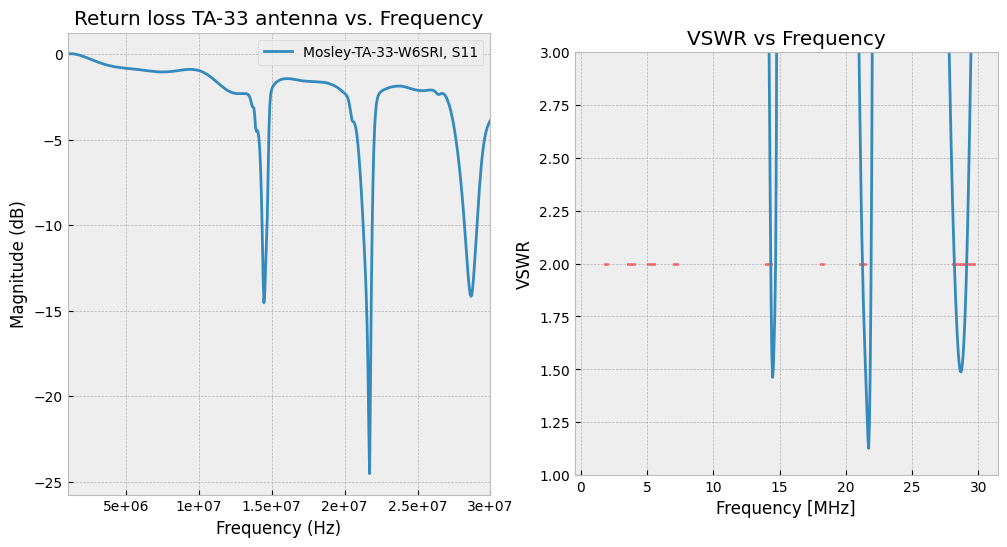

In [6]:
# load the antenna
ant = rf.Network(antenna_files / "Mosley-TA-33-W6SRI.s1p")

# plot the return loss of the antenna
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
ax = axes[0]
ant.plot_s_db(ax=ax)
ax.grid(True)
ax.set_title("Return loss TA-33 antenna vs. Frequency")

# plot the VSWR vs freq
vswr = s11_to_vswr(ant.s[:, 0, 0])

ax = axes[1]
ax.plot(freq_range.f/1e6, ham_freqs*0 + 2, color='red', alpha=0.5)
ax.fill_between(ham_freqs*0 + 1, ham_freqs*0 + 10)
ax.plot(ant.frequency.f / 1e6, vswr)


ax.set_ylim(1, 3)
ax.grid(True)
ax.set_xlabel("Frequency [MHz]")
ax.set_ylabel("VSWR")
ax.set_title("VSWR vs Frequency")
ax.set_box_aspect(1)

plt.plot()

In [7]:
# Z-match settings used for calibration
Ls = (1, 3, 5, 7, 9)
Ts = (1, 3, 5, 7, 9)

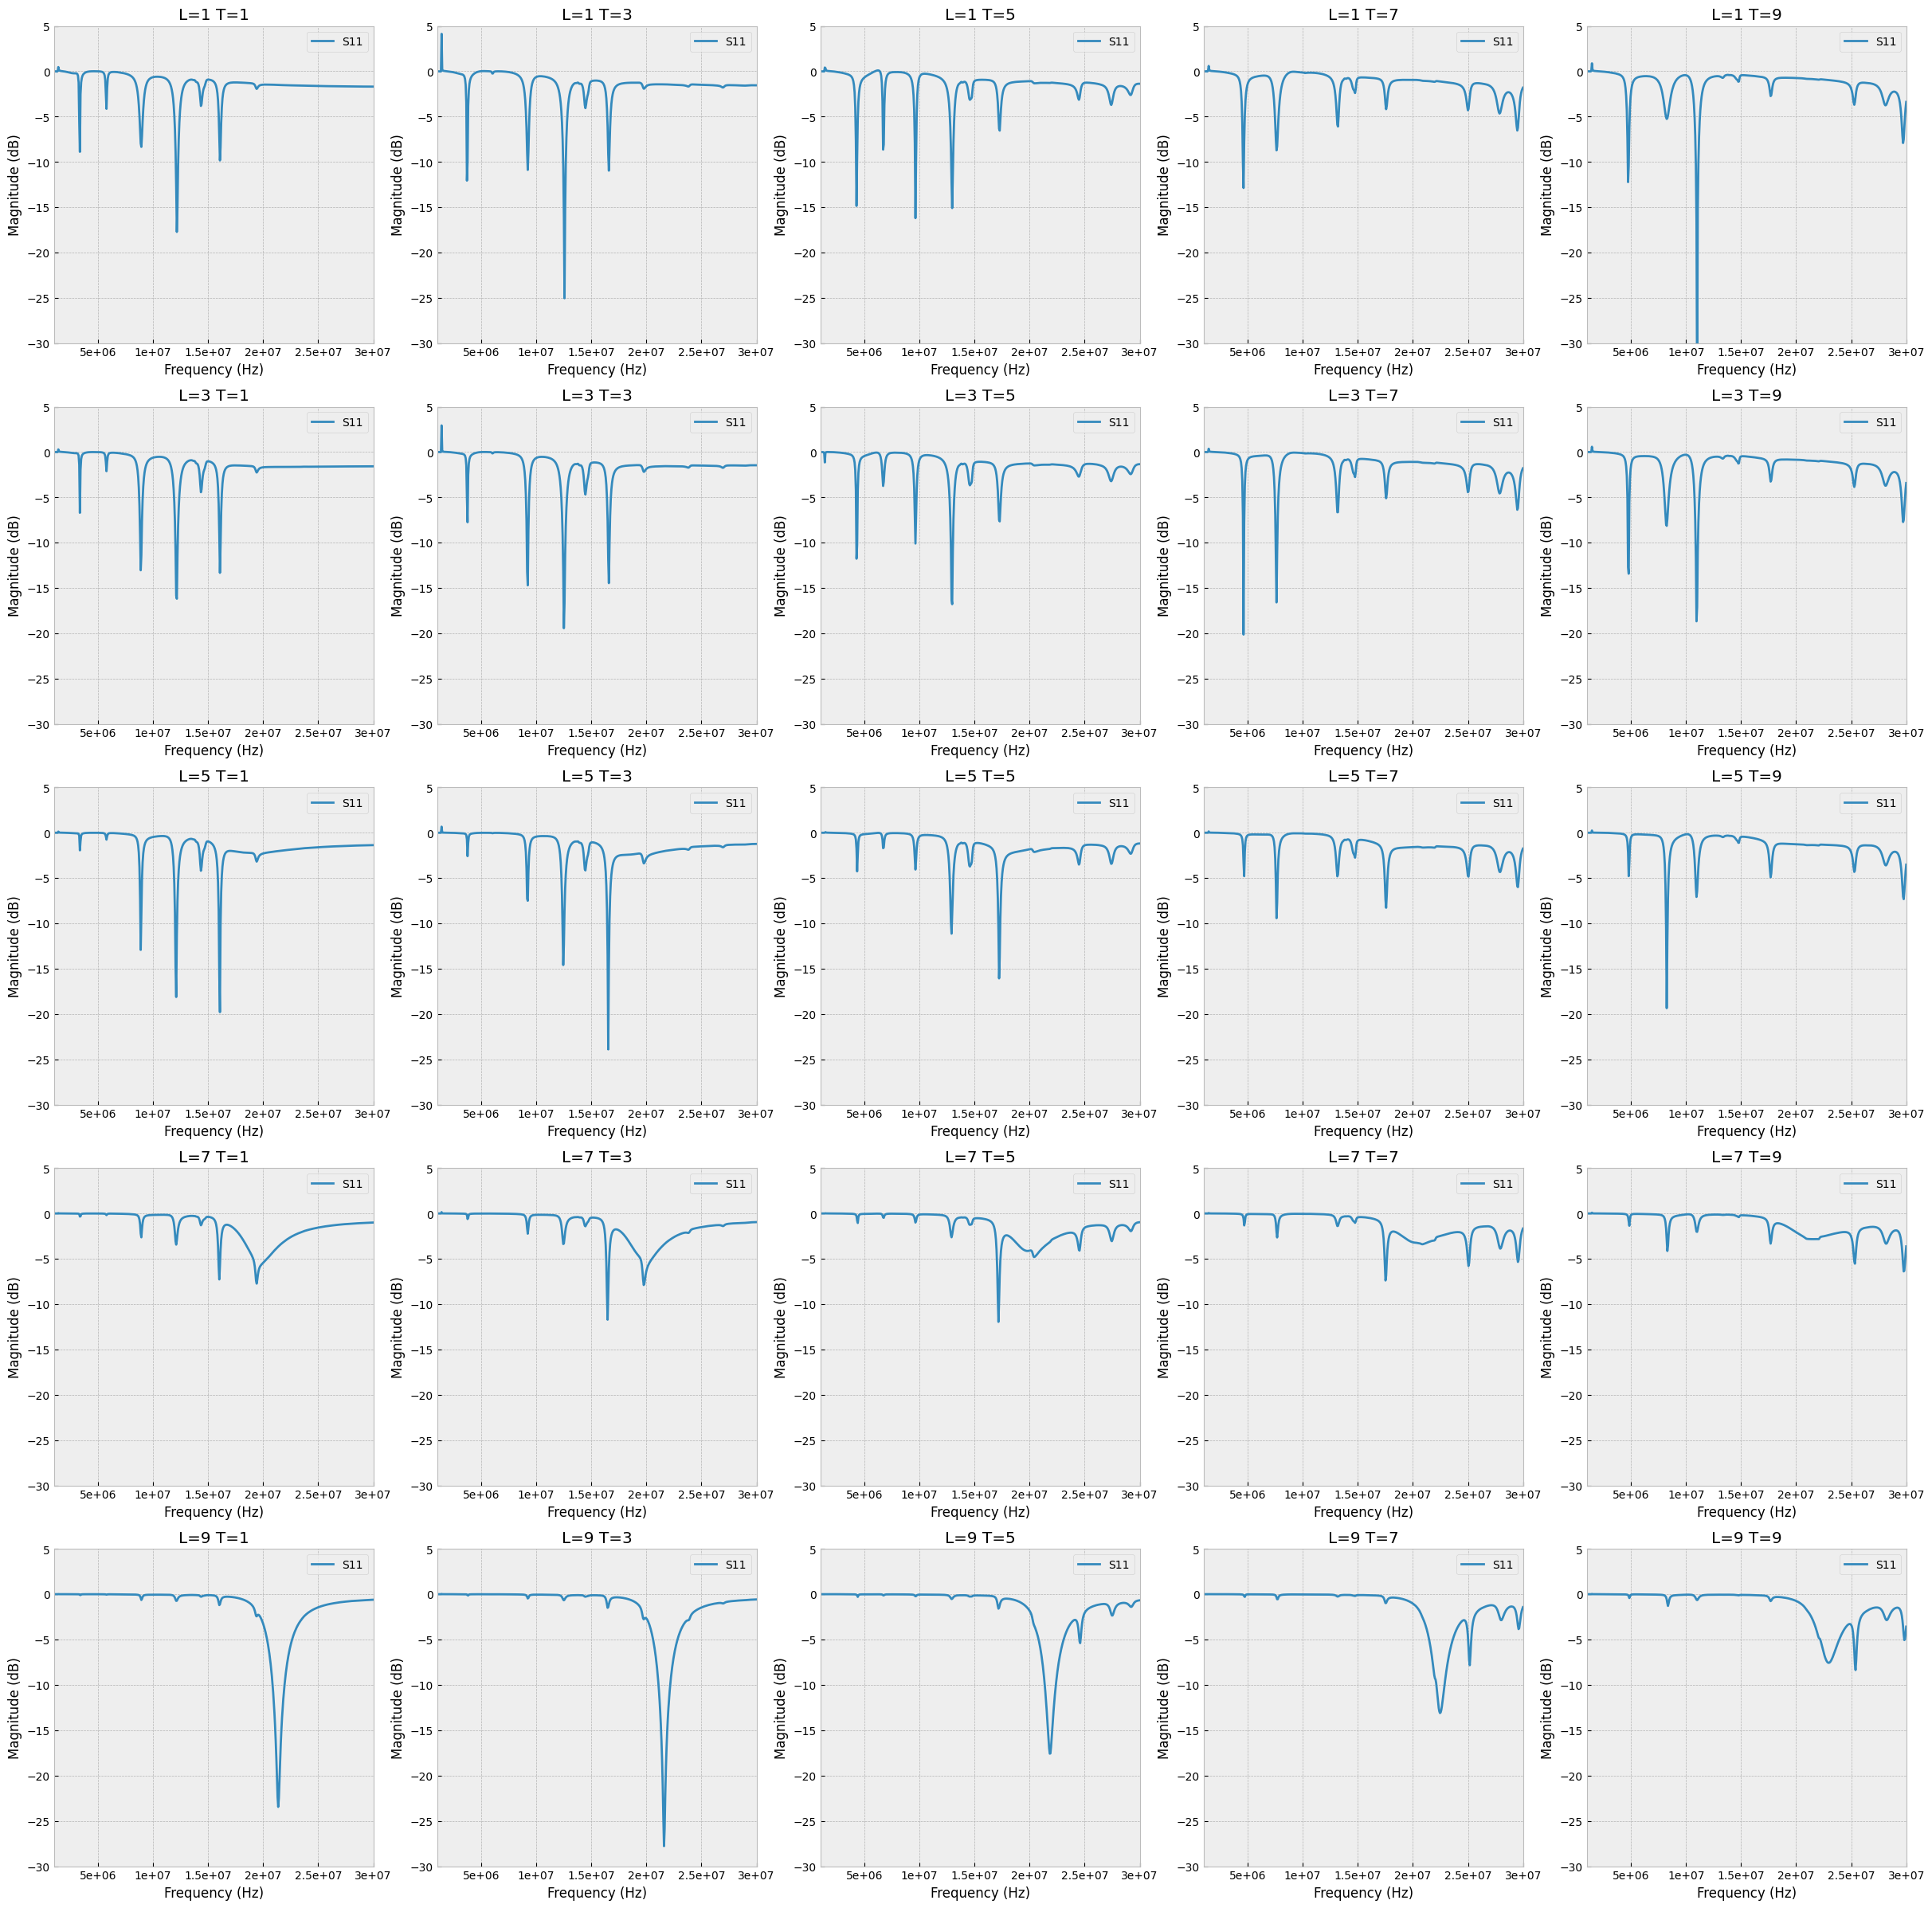

In [8]:
# Plot return loss for the tuner settings
# set up big plot
fig, axes = plt.subplots(len(Ls), len(Ts), figsize=(30, 30))

# iterate over settings
for li, l in enumerate(Ls):
    for ti, t in enumerate(Ts):

        # load the forward and reverse s2p sweeps
        zm_f, zm_r = [
            rf.Network(tuner_files / "zmatch" / f"zmatch-L{l}-T{t}-{dir}.s2p")
            for dir in ("F", "R")
        ]

        # merge into a single two-port network
        tuner = rf.network.four_oneports_2_twoport(
            s11=zm_f.s11, s12=zm_r.s21, s21=zm_f.s21, s22=zm_r.s11
        )

        # cascade the tuner and antenna networks
        tuner_ant = tuner**ant

        # plot return loss of the combined network
        ax = axes[li, ti]
        tuner_ant.plot_s_db(ax=ax)
        ax.set_title(f"L={l} T={t}")
        ax.grid(True)
        ax.set_ylim((-30, +5))

plt.show()

In [31]:
reflection_coefficients = np.zeros(
    (len(Ls), len(Ts), len(ant.frequency.f)), dtype=ant.s11.s.dtype
)
for li, l in enumerate(Ls):
    for ti, t in enumerate(Ts):

        # load the forward and reverse s2p sweeps
        zm_f, zm_r = [
            rf.Network(tuner_files / "zmatch" / f"zmatch-L{l}-T{t}-{dir}.s2p")
            for dir in ("F", "R")
        ]

        # merge into a single two-port network
        tuner = rf.network.four_oneports_2_twoport(
            s11=zm_f.s11, s12=zm_r.s21, s21=zm_f.s21, s22=zm_r.s11
        )

        # cascade the tuner and antenna networks
        tuner_ant = tuner**ant

        reflection_coefficients[li, ti, :] = tuner_ant.s11.s[:, 0, 0]

In [32]:
fi = np.searchsorted(tuner_ant.frequency.f, 28070e3)

rc_f = reflection_coefficients[:, :, fi]

rc_f

array([[0.32721705-0.75729656j, 0.38010482-0.74608737j,
        0.51239072-0.64957596j, 0.48814518-0.43969124j,
        0.44983617-0.46786309j],
       [0.33967725-0.76079151j, 0.38857887-0.74878734j,
        0.5123773 -0.64951721j, 0.48473131-0.44517826j,
        0.44812461-0.4738646j ],
       [0.36231019-0.76821451j, 0.41146914-0.75580436j,
        0.52364484-0.65631974j, 0.47635725-0.45964488j,
        0.44376482-0.49256142j],
       [0.41018302-0.77848515j, 0.44576254-0.76334216j,
        0.53424868-0.66875386j, 0.46378011-0.49078008j,
        0.4405576 -0.52863288j],
       [0.48128828-0.7823204j , 0.50927958-0.76749424j,
        0.55870983-0.68471787j, 0.45996178-0.563787j  ,
        0.44933845-0.58238603j]])

In [33]:
fr.freq_to_band(28070)["band"]

10

In [34]:
is_ham_frequency(28070e3)

10